# Лабораторная работа №3. Свёртка, separable filters и частотная интерпретация

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №3».

**Данные.** `data/building.jpg` в оттенках серого (пример из набора OpenCV).

## 1. О чём эта работа

### Знакомый пример

Размытие фона в портретном режиме, «резкость» в редакторе, сглаживание шумной ночной фотографии — всё это одна и та же операция. Каждый пиксель заменяется на взвешенную сумму себя и соседей. Меняется только набор весов.

### Основная идея

Берём маленькую табличку весов (например, 3×3) — **ядро**. Прикладываем её к картинке так, чтобы центр ядра лёг на пиксель. Перемножаем числа ядра с числами картинки под ними, складываем — получаем новое значение пикселя. Сдвигаем ядро на один пиксель и повторяем. Если все веса равны 1/9 — это усреднение (размытие). Если слева −1, справа +1 — это «насколько справа светлее, чем слева» (поиск вертикальных границ).

### Понятия

- **Ядро (kernel, фильтр)** $K$ — маленькая матрица весов.
- **Корреляция** — описанная выше операция «приложил, перемножил, сложил».
- **Свёртка** — то же самое, но ядро предварительно повёрнуто на 180°. Для симметричных ядер (усреднение, Гаусс) разницы нет. В компьютерном зрении «свёрткой» часто называют именно корреляцию.
- **Padding** — что делать на краю, где ядро вылезает за картинку. `zero` — считать, что снаружи нули (край темнеет); `reflect` — зеркально отразить картинку.
- **Линейный оператор** — операция, для которой «фильтр от суммы = сумма фильтров»: $F(aI_1+bI_2)=aF(I_1)+bF(I_2)$. Корреляция линейна, медианный фильтр — нет.
- **Ранг матрицы** — сколько в ней по-настоящему независимых строк. Ранг 1 означает, что все строки — одна и та же строка, умноженная на разные числа.
- **Сепарабельное ядро** — ядро ранга 1. Его можно записать как столбец, умноженный на строку: $K=ab^T$. Тогда вместо одного двумерного прохода можно сделать два одномерных: сначала по строкам фильтром $b$, потом по столбцам фильтром $a$.
- **Частота** в изображении — как быстро меняется яркость. Ровное небо — низкая частота; мелкая сетка, шум, резкий край — высокая. Сглаживание убирает высокие частоты, поэтому его называют **low-pass** (фильтр нижних частот).

### Формулы

Корреляция:

$$Y[i,j]=\sum_m\sum_n I[i+m,\,j+n]\,K[m,n]$$

$I$ — изображение, $K$ — ядро, $m,n$ пробегают позиции внутри ядра, $Y$ — результат.

Сепарабельность: $K=ab^T$ при $\mathrm{rank}(K)=1$. Для ядра $k\times k$ двумерный проход — $k^2$ умножений на пиксель, два одномерных — $2k$.

Частотная характеристика одномерного фильтра $h$:

$$H(\omega)=\sum_n h[n]\,e^{-j\omega n}$$

$\omega$ — частота в радианах на пиксель: $\omega=0$ — постоянный сигнал, $\omega=\pi$ — самый быстрый возможный сигнал «+1, −1, +1, −1…». $|H(\omega)|$ показывает, во сколько раз фильтр ослабляет волну этой частоты. $j$ — мнимая единица; $e^{-j\omega n}$ — способ записать «волну частоты $\omega$» одним комплексным числом.

In [1]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "gray"})

IMAGE_PATH = "data/building.jpg"
PADDING = "reflect"          # тип padding для всей работы
N_RUNS = 20                  # число запусков при замере времени
NOISE_SIGMA = 20.0
rng = np.random.default_rng(0)

## 2. Вопрос 1 — корреляция в центре

> Для `I=[[1,2,3],[4,5,6],[7,8,9]]` и `K=[[1,0,−1],[1,0,−1],[1,0,−1]]` вычислите корреляцию в центре.

Ядро 3×3 кладём точно на матрицу 3×3 и перемножаем поэлементно:

| | столбец 1 (×1) | столбец 2 (×0) | столбец 3 (×−1) |
|---|---|---|---|
| строка 1 | $1\cdot1=1$ | $2\cdot0=0$ | $3\cdot(-1)=-3$ |
| строка 2 | $4\cdot1=4$ | $5\cdot0=0$ | $6\cdot(-1)=-6$ |
| строка 3 | $7\cdot1=7$ | $8\cdot0=0$ | $9\cdot(-1)=-9$ |

Сумма: $1-3+4-6+7-9=-6$.

**Смысл.** Ядро считает «сумма левого столбца минус сумма правого»: $(1+4+7)-(3+6+9)=12-18=-6$. Отрицательный результат означает, что справа ярче, чем слева. Это ядро Прюитта — детектор вертикальных границ.

**Корреляция и свёртка здесь отличаются.** Для свёртки ядро поворачивается на 180° и превращается в `[[−1,0,1],…]`, результат меняет знак: $+6$.

In [2]:
I3 = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]], dtype=float)
K_prewitt = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], dtype=float)

print("поэлементные произведения:\n", I3 * K_prewitt)
print("корреляция в центре:", (I3 * K_prewitt).sum())
print("свёртка в центре   :", (I3 * K_prewitt[::-1, ::-1]).sum(), "(ядро повёрнуто на 180°)")

поэлементные произведения:
 [[ 1.  0. -3.]
 [ 4.  0. -6.]
 [ 7.  0. -9.]]
корреляция в центре: -6.0
свёртка в центре   : 6.0 (ядро повёрнуто на 180°)


**Итог вопроса 1:** $-6$.

## 3. Вопрос 2 — сепарабельность и частотная характеристика

> Докажите, что `(1/16)[[1,2,1],[2,4,2],[1,2,1]]` сепарабельно. Для `h=[1/2,1/2]` найдите |H(0)| и |H(π)|.

### Сепарабельность

Посмотрим на строки: вторая строка `[2,4,2]` — это первая `[1,2,1]`, умноженная на 2; третья совпадает с первой. Все строки пропорциональны одной — значит, ранг равен 1. Запишем явно:

$$\frac1{16}\begin{bmatrix}1&2&1\\2&4&2\\1&2&1\end{bmatrix}=\frac14\begin{bmatrix}1\\2\\1\end{bmatrix}\cdot\frac14\begin{bmatrix}1&2&1\end{bmatrix}$$

Проверка одного элемента: центральный $=\frac14\cdot2\cdot\frac14\cdot2=\frac4{16}$ ✓.

**Почему из этого следует «два одномерных прохода».** Подставим $K[m,n]=a[m]\,b[n]$ в формулу корреляции:

$$Y[i,j]=\sum_m a[m]\Big(\sum_n I[i+m,j+n]\,b[n]\Big)$$

Скобка — это фильтрация строк ядром $b$. Внешняя сумма — фильтрация результата по столбцам ядром $a$. Для ядра 3×3 это 6 умножений вместо 9, для 15×15 — 30 вместо 225.

### Частотная характеристика

$h=[1/2,1/2]$ — среднее двух соседних отсчётов: $y[n]=\frac12x[n]+\frac12x[n-1]$.

$$H(\omega)=\frac12e^{-j\omega\cdot0}+\frac12e^{-j\omega\cdot1}=\frac12+\frac12e^{-j\omega}$$

- $\omega=0$: $e^{0}=1$, $H(0)=\frac12+\frac12=1$, $|H(0)|=1$.
- $\omega=\pi$: $e^{-j\pi}=-1$, $H(\pi)=\frac12-\frac12=0$, $|H(\pi)|=0$.

**Проверка без комплексных чисел.** Постоянный сигнал `5,5,5,5`: среднее соседей — снова 5, сигнал прошёл без изменений (усиление 1). Сигнал `+1,−1,+1,−1`: среднее соседей — всегда 0, сигнал уничтожен (усиление 0). Фильтр пропускает медленное и гасит быстрое — это и есть low-pass. В общем виде $|H(\omega)|=|\cos(\omega/2)|$ — плавно убывает от 1 до 0.

rank(K) = 1
a·aᵀ == K: True
сингулярные числа: [0.375 0.    0.   ]
из SVD: a = [-0.25 -0.5  -0.25]  b = [-0.25 -0.5  -0.25] (знак общий, произведение то же)
rank ядра Прюитта из вопроса 1: 1 — тоже сепарабельно: [1,1,1]ᵀ·[1,0,−1]

|H(0)| = 1.0   |H(π)| = 0.0
на сигналах: const → [5. 5. 5. 5. 5.]   чередование → [0. 0. 0. 0. 0.]


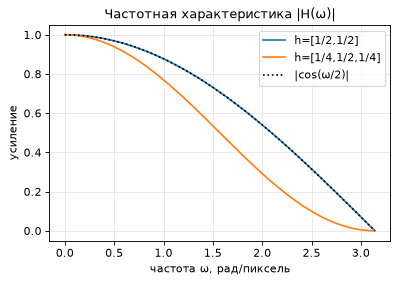

In [3]:
K_gauss = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=float) / 16
a = np.array([1, 2, 1], dtype=float) / 4
print("rank(K) =", np.linalg.matrix_rank(K_gauss))
print("a·aᵀ == K:", np.allclose(np.outer(a, a), K_gauss))

# общий способ найти разложение: SVD. Для rank-1 ненулевое сингулярное число одно.
U, S, Vt = np.linalg.svd(K_gauss)
print("сингулярные числа:", S)
a_svd, b_svd = U[:, 0] * np.sqrt(S[0]), Vt[0] * np.sqrt(S[0])
print("из SVD: a =", a_svd, " b =", b_svd, "(знак общий, произведение то же)")
print("rank ядра Прюитта из вопроса 1:", np.linalg.matrix_rank(K_prewitt), "— тоже сепарабельно: [1,1,1]ᵀ·[1,0,−1]")

h = np.array([0.5, 0.5])
def H(omega, h):
    n = np.arange(len(h))
    return (h * np.exp(-1j * omega * n)).sum()

print("\n|H(0)| =", abs(H(0, h)), "  |H(π)| =", round(abs(H(np.pi, h)), 12))
print("на сигналах: const →", np.convolve(np.full(6, 5.0), h, "valid"), "  чередование →", np.convolve(np.array([1, -1, 1, -1, 1, -1.0]), h, "valid"))

om = np.linspace(0, np.pi, 200)
plt.figure(figsize=(5.5, 3.5))
plt.plot(om, [abs(H(w, h)) for w in om], label="h=[1/2,1/2]")
plt.plot(om, [abs(H(w, a)) for w in om], label="h=[1/4,1/2,1/4]")
plt.plot(om, np.abs(np.cos(om / 2)), "k:", label="|cos(ω/2)|")
plt.title("Частотная характеристика |H(ω)|"); plt.xlabel("частота ω, рад/пиксель"); plt.ylabel("усиление")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Итог вопроса 2:** ядро равно $\frac1{16}[1,2,1]^T[1,2,1]$, ранг 1 — сепарабельно; $|H(0)|=1$, $|H(\pi)|=0$.

## 4. Задание 3 — код и эксперимент

### Шаги 1–4. ROI 64×64, padding, двойной цикл, проверка на вопросе 1

Padding во всей работе — **reflect** (зеркальное отражение без повторения крайнего пикселя; в OpenCV это `BORDER_REFLECT_101`, значение по умолчанию). Выбран потому, что нулевой padding затемняет края после сглаживания.

Отлаживаем на маленьком фрагменте: двойной цикл на Python медленный, и ошибку индексов проще увидеть на маленькой матрице.

In [4]:
def correlate2d(gray, K, mode=PADDING):
    """2D-корреляция двойным циклом: в каждом пикселе сумма произведений окна на ядро."""
    kh, kw = K.shape
    ph, pw = kh // 2, kw // 2
    x = np.pad(gray, ((ph, ph), (pw, pw)), mode=mode).astype(float)
    out = np.zeros(gray.shape, dtype=float)
    for i in range(gray.shape[0]):
        for j in range(gray.shape[1]):
            out[i, j] = np.sum(x[i:i + kh, j:j + kw] * K)
    return out

# шаг 4: проверка на матрице вопроса 1 — центр должен дать −6
print("correlate2d(I3, K)[1,1] =", correlate2d(I3, K_prewitt)[1, 1])

gray = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE).astype(np.float64)
roi = gray[250:314, 400:464]              # ROI 64×64 для отладки
print("изображение:", gray.shape, " ROI:", roi.shape)

mine = correlate2d(roi, K_gauss)
ref = cv2.filter2D(roi, -1, K_gauss, borderType=cv2.BORDER_REFLECT_101)
print("max |своя − cv2.filter2D| на ROI:", np.abs(mine - ref).max())

correlate2d(I3, K)[1,1] = -6.0
изображение: (600, 868)  ROI: (64, 64)
max |своя − cv2.filter2D| на ROI: 0.0


### Шаги 5–6. Сепарабельная версия и сравнение

Два прохода тем же способом (цикл по пикселям), только окно теперь одномерное: сначала вдоль строки, затем вдоль столбца.

In [5]:
def correlate_separable(gray, a_col, b_row, mode=PADDING):
    """Два 1D-прохода: по строкам ядром b_row, затем по столбцам ядром a_col."""
    H_, W_ = gray.shape
    kb, ka = len(b_row), len(a_col)
    x = np.pad(gray, ((0, 0), (kb // 2, kb // 2)), mode=mode).astype(float)
    tmp = np.zeros((H_, W_))
    for i in range(H_):
        for j in range(W_):
            tmp[i, j] = np.sum(x[i, j:j + kb] * b_row)
    x = np.pad(tmp, ((ka // 2, ka // 2), (0, 0)), mode=mode)
    out = np.zeros((H_, W_))
    for i in range(H_):
        for j in range(W_):
            out[i, j] = np.sum(x[i:i + ka, j] * a_col)
    return out

sep = correlate_separable(roi, a, a)
print("max |2D − separable| на ROI:", np.abs(mine - sep).max())

max |2D − separable| на ROI: 0.0


Разность нулевая или порядка $10^{-13}$ — это погрешность округления чисел с плавающей точкой (сложения выполняются в другом порядке); математически результаты одинаковы.

### Шаг 7. Замер времени

Два замера. Первый — как в задании: обе цикловые реализации, 20 запусков, ядро 3×3. Второй — векторная реализация на всём изображении для ядер разного размера: в ней время пропорционально числу умножений на пиксель, поэтому закон «$k^2$ против $2k$» виден в чистом виде.

In [6]:
def timeit(fn, runs=N_RUNS):
    ts = []
    for _ in range(runs):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return 1000 * np.median(ts), 1000 * np.std(ts)

t2d = timeit(lambda: correlate2d(roi, K_gauss))
tsep = timeit(lambda: correlate_separable(roi, a, a))
print(f"цикл 2D, ядро 3×3, ROI 64×64      : {t2d[0]:7.2f} ± {t2d[1]:.2f} ms")
print(f"цикл separable, ядро 3×3, ROI 64×64: {tsep[0]:7.2f} ± {tsep[1]:.2f} ms")
print("умножений на пиксель: 9 против 6; но циклов по пикселям — один против двух")

def corr_vec(gray, K):
    """Векторная корреляция: k² сдвинутых копий изображения, сложенных с весами."""
    kh, kw = K.shape
    x = np.pad(gray, ((kh // 2,) * 2, (kw // 2,) * 2), mode=PADDING)
    out = np.zeros_like(gray)
    for m in range(kh):
        for n in range(kw):
            out += K[m, n] * x[m:m + gray.shape[0], n:n + gray.shape[1]]
    return out

def corr_vec_sep(gray, a_col, b_row):
    return corr_vec(corr_vec(gray, b_row[None, :]), a_col[:, None])

def gauss1d(k, sigma):
    r = np.arange(k) - k // 2
    g = np.exp(-r ** 2 / (2 * sigma ** 2))
    return g / g.sum()

print(f"\nвекторная реализация, всё изображение {gray.shape}:")
print(f"{'k':>3}{'2D, ms':>10}{'separable, ms':>16}{'ускорение':>11}{'k²/2k':>8}{'max |Δ|':>12}")
timing = []
for k in (3, 5, 9, 15, 21):
    g = gauss1d(k, k / 6)
    K2 = np.outer(g, g)
    ta, tb = timeit(lambda: corr_vec(gray, K2), 5)[0], timeit(lambda: corr_vec_sep(gray, g, g), 5)[0]
    d = np.abs(corr_vec(gray, K2) - corr_vec_sep(gray, g, g)).max()
    timing.append((k, ta, tb))
    print(f"{k:3d}{ta:10.1f}{tb:16.1f}{ta / tb:11.2f}{k / 2:8.1f}{d:12.2e}")

цикл 2D, ядро 3×3, ROI 64×64      :   12.69 ± 0.35 ms
цикл separable, ядро 3×3, ROI 64×64:   18.89 ± 0.23 ms
умножений на пиксель: 9 против 6; но циклов по пикселям — один против двух

векторная реализация, всё изображение (600, 868):
  k    2D, ms   separable, ms  ускорение   k²/2k     max |Δ|
  3      13.1            11.0       1.19     1.5    1.42e-13


  5      32.3            15.4       2.10     2.5    1.42e-13


  9      98.5            24.6       4.00     4.5    2.84e-13


 15     275.3            40.5       6.79     7.5    4.83e-13


 21     560.9            55.8      10.06    10.5    7.11e-13


### Шаг 8. Шум и сравнение box / Gaussian / median

**PSNR** (пиковое отношение сигнал/шум) — стандартная мера «насколько восстановленное изображение близко к чистому»:

$$\mathrm{MSE}=\frac1N\sum(\hat I-I)^2,\qquad \mathrm{PSNR}=10\log_{10}\frac{255^2}{\mathrm{MSE}}\ \text{дБ}$$

Больше — лучше; +3 дБ означает вдвое меньшую MSE. Box и Gaussian считаем своей функцией, медиану — `cv2.medianBlur` (медиана не является корреляцией: это сортировка окна, а не взвешенная сумма).

гауссов шум σ=20.0
фильтр                         MSE   PSNR, dB
шумное (без фильтра)         353.1      22.65
box 5×5                      127.2      27.09
Gaussian 5×5, σ=1             67.1      29.86
median 5×5                   101.4      28.07


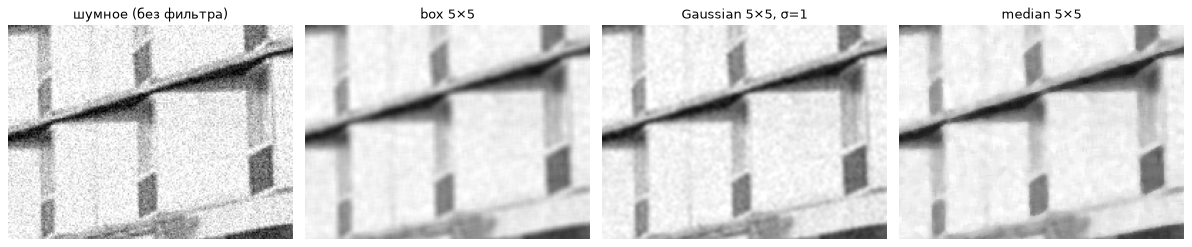

In [7]:
def psnr(x, ref):
    mse = np.mean((x.astype(float) - ref.astype(float)) ** 2)
    return 10 * np.log10(255 ** 2 / mse), mse

noisy = gray + rng.normal(0, NOISE_SIGMA, gray.shape)
noisy_u8 = np.clip(noisy, 0, 255).astype(np.uint8)

box5 = np.full(5, 1 / 5)
g5 = gauss1d(5, 1.0)
results = {
    "шумное (без фильтра)": noisy,
    "box 5×5": corr_vec_sep(noisy, box5, box5),
    "Gaussian 5×5, σ=1": corr_vec_sep(noisy, g5, g5),
    "median 5×5": cv2.medianBlur(noisy_u8, 5).astype(float),
}
print(f"гауссов шум σ={NOISE_SIGMA}")
print(f"{'фильтр':24}{'MSE':>10}{'PSNR, dB':>11}")
for name, im in results.items():
    p, m = psnr(np.clip(im, 0, 255), gray)
    print(f"{name:24}{m:10.1f}{p:11.2f}")

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
crop = (slice(230, 380), slice(380, 580))
for a_, (name, im) in zip(ax, results.items()):
    a_.imshow(im[crop], vmin=0, vmax=255); a_.set_title(name); a_.axis("off")
plt.tight_layout(); plt.show()

### Шаги 9–10. Спектр до и после сглаживания

**Преобразование Фурье** раскладывает картинку на волны разных частот и направлений. На картинке спектра центр — нулевая частота (средняя яркость), чем дальше от центра — тем выше частота. Яркость точки — амплитуда соответствующей волны. Амплитуды различаются на много порядков, поэтому показываем логарифм.

Третья картинка — частотная характеристика самого ядра (его спектр): по теореме о свёртке спектр результата равен спектру изображения, умноженному на спектр ядра.

FFT считает картинку периодической: правый край «склеивается» с левым. Яркости на противоположных краях разные, и на склейке возникает скачок, который даёт в спектре ложный яркий крест через все частоты. Чтобы он не мешал измерению, перед FFT картинку умножают на **окно Ханна** — плавный спад до нуля к краям.

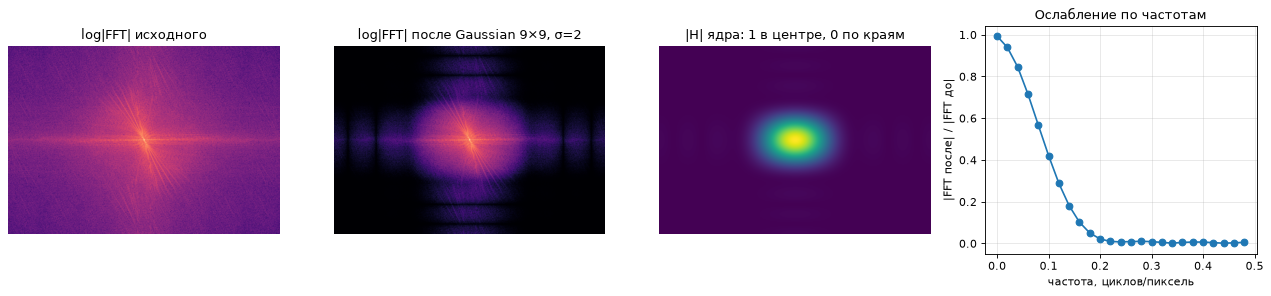

доля амплитуды, оставшаяся на низких частотах (<0.04): 0.993
на средних (0.10–0.12): 0.421   на высоких (0.30–0.32): 0.00901


In [8]:
WIN = np.outer(np.hanning(gray.shape[0]), np.hanning(gray.shape[1]))   # окно Ханна

def spectrum(im):
    return np.abs(np.fft.fftshift(np.fft.fft2(im * WIN)))

def log_spectrum(im):
    return np.log1p(spectrum(im))

g9 = gauss1d(9, 2.0)
smooth = corr_vec_sep(gray, g9, g9)

Kpad = np.zeros(gray.shape); Kpad[:9, :9] = np.outer(g9, g9)
resp = np.abs(np.fft.fftshift(np.fft.fft2(Kpad)))

S0, S1 = log_spectrum(gray), log_spectrum(smooth)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
ax[0].imshow(S0, cmap="magma", vmin=0, vmax=S0.max()); ax[0].set_title("log|FFT| исходного")
ax[1].imshow(S1, cmap="magma", vmin=0, vmax=S0.max()); ax[1].set_title("log|FFT| после Gaussian 9×9, σ=2")
ax[2].imshow(resp, cmap="viridis"); ax[2].set_title("|H| ядра: 1 в центре, 0 по краям")
for a_ in ax[:3]: a_.axis("off")

# энергия спектра по кольцам: во сколько раз ослаблена каждая частота
F0, F1 = spectrum(gray), spectrum(smooth)
yy, xx = np.indices(gray.shape)
fy = (yy - gray.shape[0] // 2) / gray.shape[0]; fx = (xx - gray.shape[1] // 2) / gray.shape[1]
rad = np.sqrt(fx ** 2 + fy ** 2)                     # частота в циклах на пиксель, максимум 0.5 по оси
bins = np.linspace(0, 0.5, 26)
ratio = [F1[(rad >= lo) & (rad < hi)].sum() / F0[(rad >= lo) & (rad < hi)].sum() for lo, hi in zip(bins[:-1], bins[1:])]
ax[3].plot(bins[:-1], ratio, "o-")
ax[3].set(title="Ослабление по частотам", xlabel="частота, циклов/пиксель", ylabel="|FFT после| / |FFT до|"); ax[3].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("доля амплитуды, оставшаяся на низких частотах (<0.04):", round(ratio[0] + 0, 3))
print("на средних (0.10–0.12):", round(ratio[5], 3), "  на высоких (0.30–0.32):", round(ratio[15], 5))

После сглаживания центр спектра (низкие частоты) не изменился, а периферия потемнела: высокие частоты подавлены. Правый график показывает это числами — на низких частотах осталось почти всё, на высоких почти ничего. Форма кривой — колокол: спектр гауссова ядра сам является гауссианой.

### Таблица эксперимента

Заполняется выводом ячеек шагов 7 и 8 (числа — в самих ячейках выше; время зависит от компьютера).

| Реализация | Что измерено | Max \|Δ\| | PSNR | Комментарий |
|---|---|---|---|---|
| 2D, двойной цикл | время на ROI 64×64, шаг 7 | 0 относительно `cv2.filter2D` | — | эталон; 9 умножений на пиксель |
| separable, два цикла | время на ROI 64×64, шаг 7 | 0 | — | 6 умножений, но два прохода цикла |
| 2D векторная | время на полном кадре, k=3…21 | — | — | время растёт как k² |
| separable векторная | то же | ~1e-13 | — | время растёт как 2k |
| box / Gaussian / median 5×5 | — | — | шаг 8 | качество подавления шума |

## 5. Неудачный случай: линейный фильтр против импульсного шума

Гауссов шум — маленькие отклонения в каждом пикселе; усреднение их гасит. **Импульсный шум** («соль и перец») — редкие пиксели, ставшие чисто чёрными или белыми. Для него усреднение — плохой метод.

фильтр                         MSE   PSNR, dB
соль-перец 10 %             2332.2      14.45
box 5×5                      299.0      23.37
Gaussian 5×5, σ=1            310.0      23.22
median 5×5                    69.9      29.68


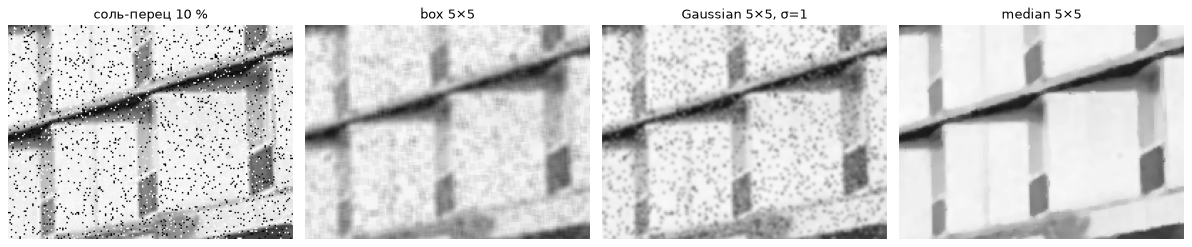

In [9]:
sp = gray.copy()
mask = rng.random(gray.shape)
sp[mask < 0.05] = 0
sp[mask > 0.95] = 255                      # 10 % пикселей испорчены

sp_res = {
    "соль-перец 10 %": sp,
    "box 5×5": corr_vec_sep(sp, box5, box5),
    "Gaussian 5×5, σ=1": corr_vec_sep(sp, g5, g5),
    "median 5×5": cv2.medianBlur(sp.astype(np.uint8), 5).astype(float),
}
print(f"{'фильтр':24}{'MSE':>10}{'PSNR, dB':>11}")
for name, im in sp_res.items():
    p, m = psnr(np.clip(im, 0, 255), gray)
    print(f"{name:24}{m:10.1f}{p:11.2f}")

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a_, (name, im) in zip(ax, sp_res.items()):
    a_.imshow(im[crop], vmin=0, vmax=255); a_.set_title(name); a_.axis("off")
plt.tight_layout(); plt.show()

Почему линейный фильтр проигрывает: выброс 255 среди значений около 100 входит во взвешенную сумму со своим весом и «размазывается» в серое пятно — ошибка не исчезает, а распределяется по соседям. Медиана сортирует окно и берёт среднее по порядку значение; пока испорченных пикселей в окне меньше половины, выброс вообще не влияет на результат. Цена — медиана нелинейна, не сепарабельна и не имеет частотной характеристики.

Второй недостаток сглаживания виден на шаге 8: вместе с шумом размываются границы — это те же высокие частоты.

## 6. Вывод

- Ручной расчёт: корреляция в центре равна −6, и функция `correlate2d` на той же матрице возвращает −6. На ROI 64×64 она совпадает с `cv2.filter2D` точно.
- **Эквивалентность.** Сепарабельная реализация даёт тот же результат, что двумерная: на ROI разность 0, на полном кадре для ядер до 21×21 — не больше 1e-12 (округление). Причина математическая: при $K=ab^T$ двойная сумма по $m,n$ распадается на сумму по $n$ внутри суммы по $m$.
- **Стоимость.** Двумерный проход — $k^2$ умножений на пиксель, два одномерных — $2k$. В векторной реализации измеренное ускорение идёт вплотную к теоретическому $k/2$: ×1.2 при $k=3$, ×2.1 при $k=5$, ×4.0 при $k=9$, ×6.8 при $k=15$, ×10 при $k=21$ (конкретные миллисекунды зависят от компьютера). В цикловой реализации на ядре 3×3 сепарабельная версия оказалась **медленнее** (≈19 ms против ≈13 ms): время там определяется не умножениями, а накладными расходами интерпретатора на каждый пиксель, а пикселей приходится обойти дважды. Сепарабельность — выигрыш в арифметике, и проявляется он там, где арифметика доминирует.
- **Гауссов шум σ=20.** PSNR шумного кадра 22.7 dB; box 5×5 — 27.1 dB, median 5×5 — 28.1 dB, Gaussian 5×5 (σ=1) — 29.9 dB. Gaussian лучше box, потому что даёт соседям убывающие веса и меньше размывает границы.
- **Импульсный шум 10 %.** Картина обратная: box и Gaussian дают ≈23.3 dB, медиана — 29.7 dB (раздел 5).
- **Частоты.** Сглаживание — умножение спектра на колоколообразную $|H|$: на низких частотах осталось 99 % амплитуды, на средних (0.10–0.12 цикла/пиксель) — 42 %, на высоких (0.30–0.32) — меньше 1 % (график шага 9–10). Шум распределён по всем частотам равномерно, а энергия изображения сосредоточена в низких — поэтому low-pass убирает больше шума, чем сигнала. Но границы и мелкие детали тоже лежат в высоких частотах и размываются.

## 7. Вопросы на защиту

**1. Чем корреляция отличается от математической свёртки?**
В свёртке ядро отражено по обеим осям: $Y[i,j]=\sum I[i-m,j-n]K[m,n]$. Для симметричного ядра результаты совпадают. Отражение нужно, чтобы операция стала коммутативной и ассоциативной ($f*g=g*f$) и чтобы выполнялась теорема «свёртка ↔ умножение спектров». `cv2.filter2D` и слои `Conv2d` в нейросетях на самом деле считают корреляцию.

**2. Почему rank-1 kernel можно вычислять двумя одномерными проходами и как меняется сложность?**
Потому что $K[m,n]=a[m]b[n]$, и двойная сумма факторизуется (вывод в разделе 3). Сложность на пиксель падает с $O(k^2)$ до $O(2k)$; для всего изображения — с $O(HWk^2)$ до $O(HWk)$. Нужна дополнительная память под промежуточное изображение.

**3. Собственный двойной цикл и обработка границ.**
В `correlate2d`: `np.pad(gray, ((ph,ph),(pw,pw)), mode='reflect')` расширяет картинку на полразмера ядра с каждой стороны, зеркально отражая содержимое (`abc|cb` → крайний пиксель не дублируется). После этого окно `x[i:i+kh, j:j+kw]` для любого пикселя исходной картинки целиком лежит внутри расширенной, и пиксель `(i,j)` исходной соответствует центру окна. Внутри цикла — поэлементное умножение окна на ядро и сумма. Размер выхода равен размеру входа.